# Biodiversity in U.S. National Parks

This project analyses National Parks Service data on endangered species to investigate conservation risk across species categories and parks.

**Questions explored:**
1. Which conservation statuses are most common across all species?
2. Are certain species categories more likely to be at risk?
3. Which national parks have the highest number of protected species?
4. Are endangered species concentrated in specific parks or spread evenly?

## 2. Data Sources & Import Libraries 

**Data Sources:**  
- Observations dataset (`observations.csv`)  
- Species dataset (`species_info.csv`)


In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


# 3. Load Data 

In [ ]:
# Load datasets  
obs = pd.read_csv('observations.csv') 
species = pd.read_csv('species_info.csv')

## 4. Exploratory Data Analysis (EDA)

In [ ]:
# Preview datasets
obs.head()
obs.info()
obs.nunique()
obs.isna().sum()
obs.duplicated().sum()

# Drop duplicates & strip whitespace
obs = obs.drop_duplicates()
obs = obs.apply(lambda col: col.str.strip() if col.dtype == 'object' else col)

species.head()
species.info()
species.isna().sum()
species.duplicated().sum()

# Fill missing conservation_status
species['conservation_status'] = species['conservation_status'].fillna('not protected')

# Lowercase & strip object columns
species['conservation_status'] = species['conservation_status'].str.lower()
species['category'] = species['category'].str.lower()
species = species.apply(lambda col: col.str.strip() if col.dtype == 'object' else col)


,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85



EDA Summary:
- Datasets contain no major missing values after filling conservation_status.
- Duplicate species were removed.
- Categories and conservation statuses are standardized in lowercase.


# 5. Data Cleaning & Merge 

In [ ]:
# Merge datasets by scientific_name
df = pd.merge(
    obs, 
    species.rename(columns={'id': 'scientific_name'}), 
    on='scientific_name', 
    how='left'
)

# Reorder columns for readability
df = df[['scientific_name', 'common_names', 'category', 'conservation_status', 'park_name', 'observations']]

# Standardize capitalization and strip whitespace
df['park_name'] = df['park_name'].str.strip().str.title()
df['scientific_name'] = df['scientific_name'].str.strip()
df['common_names'] = df['common_names'].str.strip()
df['category'] = df['category'].str.strip().str.title()
df['conservation_status'] = df['conservation_status'].str.strip().str.lower()

# Remove duplicates per species per park
df_clean = df.drop_duplicates(subset=['park_name', 'scientific_name'])

# Check duplicates & missing values
print(f'Total duplicates remaining: {df_clean.duplicated().sum()}')
print(f'Missing values per column:\n{df_clean.isna().sum()}')


The merged dataset was cleaned by stripping whitespace, standardising capitalization, and removing duplicates per park-species combination. This ensures accurate counts and visualisations.


## 6. Question 1:Which conservation status are most common across all species? 

In [ ]:
# Count number of species per conservation status 
status_counts = df_clean['conservation_status'].value_counts()

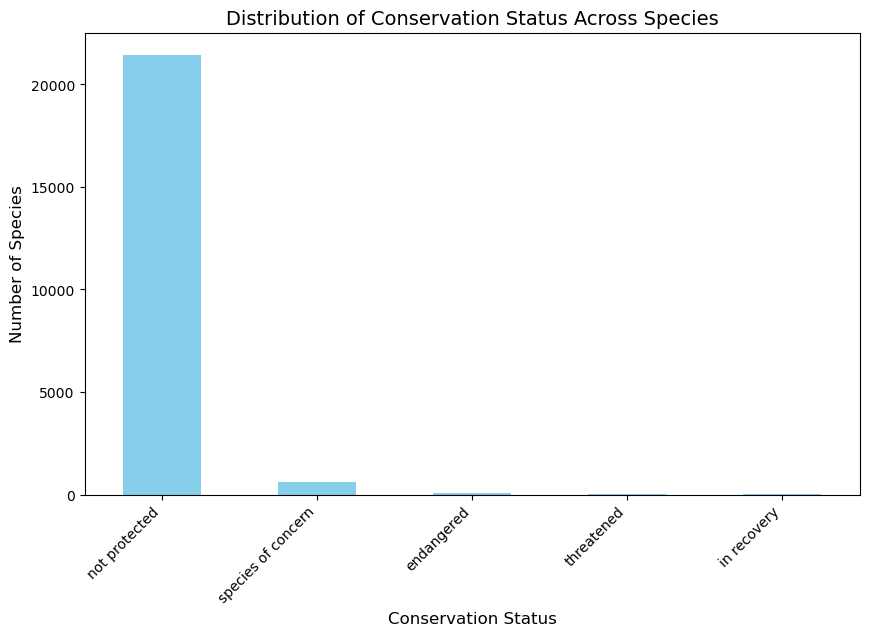

<Figure size 640x480 with 0 Axes>

In [ ]:
# Plot bar chart 
fig, ax = plt.subplots(figsize=(10,6))
status_counts.plot(kind='bar', ax=ax, color='skyblue')

ax.set_title('Distribution of Conservation Status Across Species', fontsize=14)
ax.set_xlabel('Conservation Status', fontsize=12)
ax.set_ylabel('Number of Species', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()
plt.clf()

**Interpretation:** 

Most species in the dataset are classified as “not protected,” followed by relatively few species listed as 'species of concern', 'endangered', 'threatened' and 'in recovery'. This shows that only a small proportion of species across national parks are under protection, highlighting where conservation efforts are focused.

# 7. Question 2: Are certain categories of species more likely to be endangered?

In [461]:
# Create at_risk column
df_clean['at_risk'] = df_clean['conservation_status'] != 'not protected'

# Deduplicate species
category_risk = df_clean[['category', 'scientific_name', 'at_risk']].drop_duplicates()

# Aggregate
summary = category_risk.groupby('category').agg(
    total_species=('scientific_name', 'nunique'),
    at_risk_species=('at_risk', 'sum')
)

summary['proportion_at_risk'] = summary['at_risk_species'] / summary['total_species']



/var/folders/9f/t890n5g517g14xfk4mz6wsx80000gn/T/ipykernel_79625/913121153.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['at_risk'] = df_clean['conservation_status'] != 'not protected'


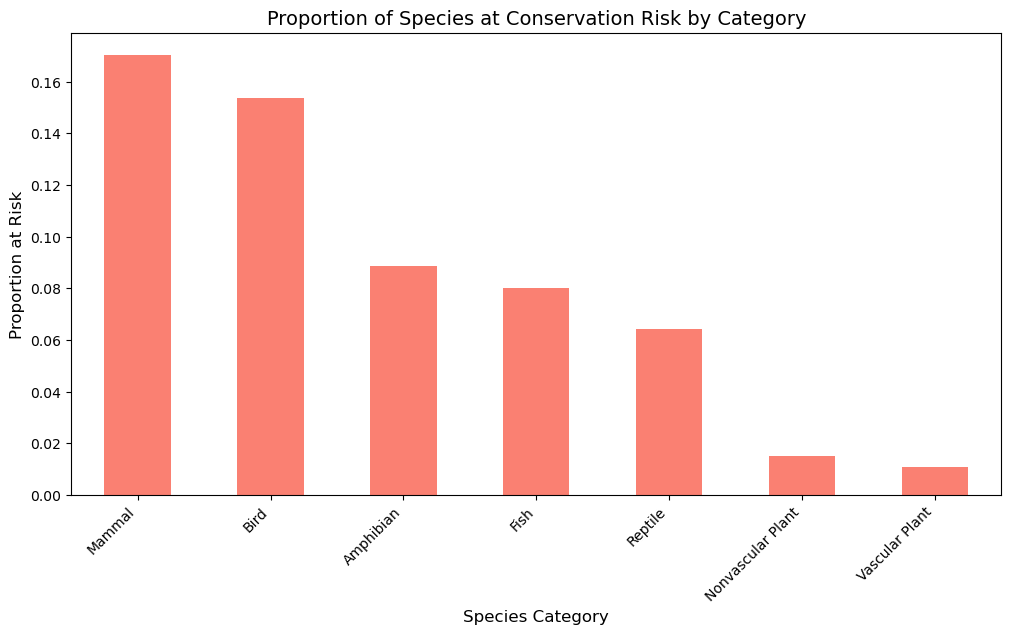

In [462]:

# Plot sorted bar chart
summary_sorted = summary.sort_values('proportion_at_risk', ascending=False)
fig, ax = plt.subplots(figsize=(12,6))
summary_sorted['proportion_at_risk'].plot(kind='bar', color='salmon', ax=ax)
ax.set_title('Proportion of Species at Conservation Risk by Category', fontsize=14)
ax.set_xlabel('Species Category', fontsize=12)
ax.set_ylabel('Proportion at Risk', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

**Interpretation:**  
Mammals and birds show the highest proportion of species at conservation risk, while plants and reptiles have lower proportions. Proportions were used to allow fair comparison across categories with different total species counts.

# 8. Question 3:  Which national parks have the highest number of protected species?

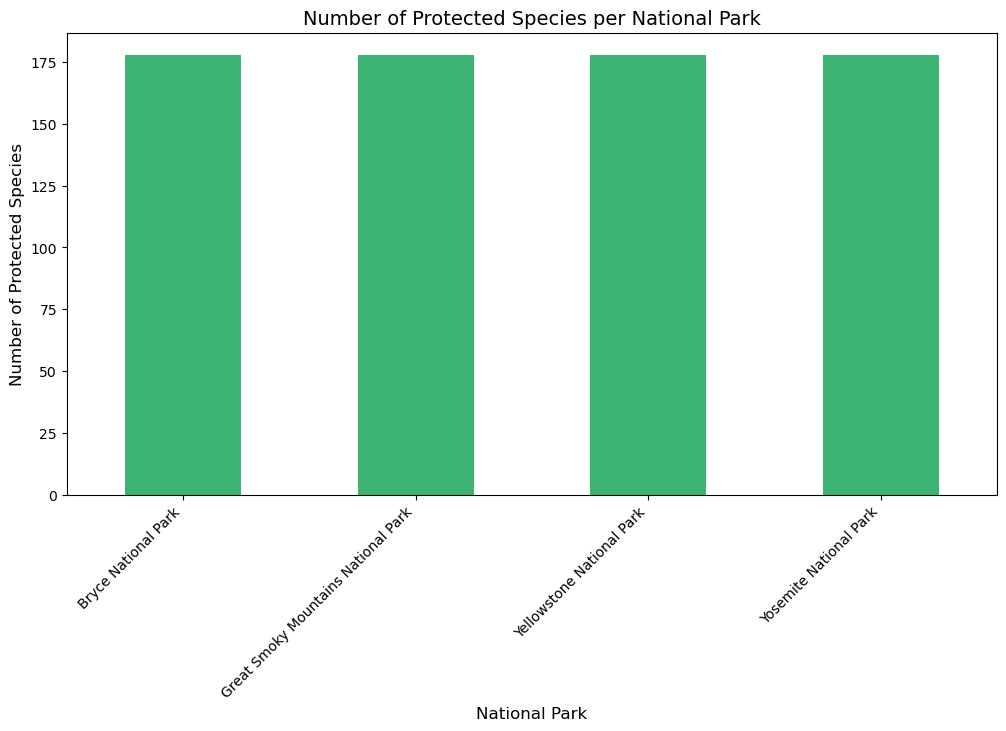

In [ ]:
# Filter protected species 
protected_species = df_clean[df_clean['conservation_status'] != 'not protected']

# Remove duplicates 
protected_unique = protected_species[['park_name', 'scientific_name']].drop_duplicates()

# Count number of species protected by park 
protected_by_park = (
    protected_unique.groupby('park_name')['scientific_name']
    .nunique()
    .sort_values(ascending=False)
)

# Plot bar chart 
fig, ax = plt.subplots(figsize=(12,6))
protected_by_park.plot(kind='bar', color='mediumseagreen', ax=ax)
ax.set_title('Number of Protected Species per National Park', fontsize=14)
ax.set_xlabel('National Park', fontsize=12)
ax.set_ylabel('Number of Protected Species', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

**Interpretation:**  
Protected species are broadly distributed across parks, with similar counts per park. This suggests that conservation efforts are relatively evenly applied across locations. Counts reflect unique species per park.

## 9. Question 4: Are endangered species concentrated in specific parks or spread evenly?

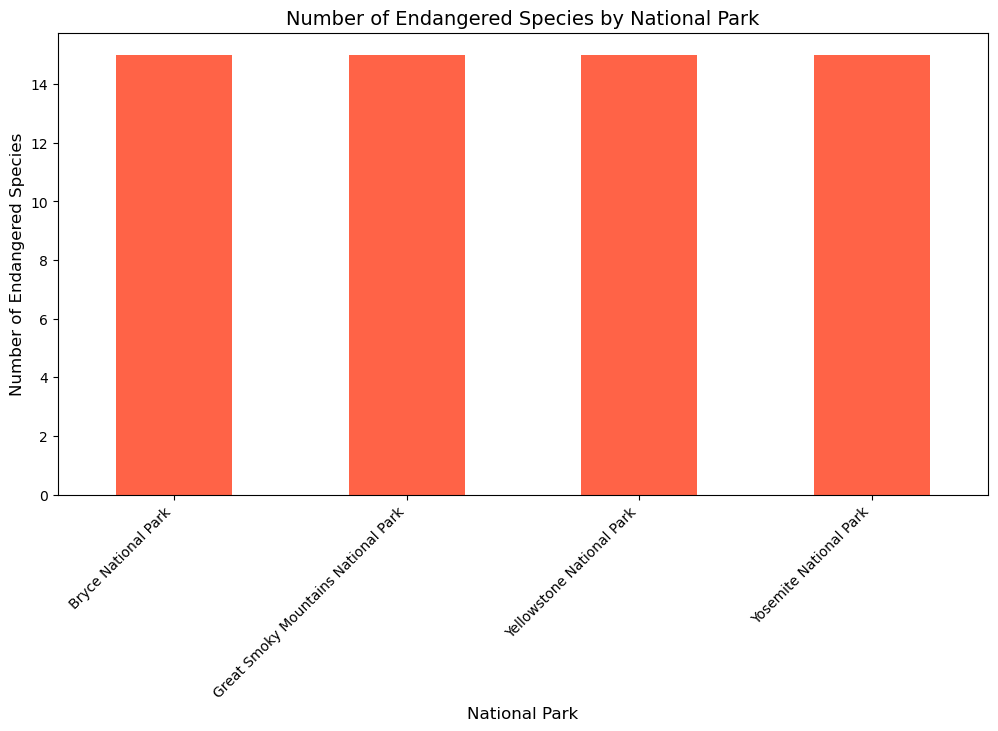

In [ ]:
# Filter endangered species 
endangered = df_clean[df_clean['conservation_status'] == 'endangered']

# Remove duplicates 
endangered_unique = endangered[['park_name', 'scientific_name']].drop_duplicates()

# Count endangered species by park 
endangered_by_park = (
    endangered_unique.groupby('park_name')['scientific_name']
    .nunique()
    .sort_values(ascending=False)
)

# Plot endangered species 
fig, ax = plt.subplots(figsize=(12,6))
endangered_by_park.plot(kind='bar', color='tomato', ax=ax)
ax.set_title('Number of Endangered Species by National Park', fontsize=14)
ax.set_xlabel('National Park', fontsize=12)
ax.set_ylabel('Number of Endangered Species', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.show()

**Interpretation:**  
Endangered species are relatively evenly distributed across national parks in this dataset. No single park shows a significantly higher concentration, although reporting standardisation may influence counts.

# 10. Limitations 

**Limitations:**
- Conservation status may vary in accuracy or completeness across species.
- Reporting structure might affect species counts across parks.
- Analysis identifies associations only; no causation inferred.

# 11. Conclusion 

**Conclusion / Key Insights:**
1. Most species are not protected; only a small fraction are at risk.
2. Mammals and birds are more likely to be at conservation risk than plants or reptiles.
3. Protected species are broadly distributed across parks, and endangered species are fairly evenly spread.
4. This project demonstrates proper data cleaning, deduplication, and professional visualisation practices.

**Next steps / portfolio enhancement ideas:**
- Explore patterns by ecosystem type or geographic region.
- Include temporal trends if observation dates are available.
- Publish cleaned dataset or summary tables in GitHub repository for reproducibility.